In [19]:
import pandas as pd
from numpy.ma.core import masked_singleton

df = pd.read_csv("../data/raw/time_series_60min_singleindex.csv")

print(f"Dataframe has {df.index.stop} rows and {len(df.columns)} columns.")
print(f"Data type of 'utc_timestamp' is '{df.dtypes["utc_timestamp"]}' and 'DE_load_actual_entsoe_transparency' is '{df.dtypes["DE_load_actual_entsoe_transparency"]}'")
print(f"The amounts of missing values: \n{df.isna().sum()}")

print("The minimal, mean and the maximal values of energy demand:")
print(df.agg({'DE_load_actual_entsoe_transparency': ['min', 'mean', 'max']}))

start = pd.to_datetime(df['utc_timestamp'].min())
end = pd.to_datetime(df['utc_timestamp'].max())
print(f"Data covers dates from {start.date()} to {end.date()}")

Dataframe has 50401 rows and 300 columns.
Data type of 'utc_timestamp' is 'str' and 'DE_load_actual_entsoe_transparency' is 'float64'
The amounts of missing values: 
utc_timestamp                               0
cet_cest_timestamp                          0
AT_load_actual_entsoe_transparency          1
AT_load_forecast_entsoe_transparency        1
AT_price_day_ahead                      17556
                                        ...  
SK_load_forecast_entsoe_transparency        3
SK_solar_generation_actual                391
SK_wind_onshore_generation_actual       40722
UA_load_actual_entsoe_transparency      24766
UA_load_forecast_entsoe_transparency    24988
Length: 300, dtype: int64
The minimal, mean and the maximal values of energy demand:
      DE_load_actual_entsoe_transparency
min                         31307.000000
mean                        55492.468552
max                         77549.000000
Data covers dates from 2014-12-31 to 2020-09-30


In [17]:
print(f"Missing% of the Energy Demand from Germany: {(sum(pd.isnull(df['DE_load_actual_entsoe_transparency'])) / df.shape[0]) * 100}%")

Missing% of the Energy Demand from Germany: 0.00198408761730918%


In [21]:
df["utc_timestamp"] = pd.to_datetime(df["utc_timestamp"], utc=True)
local_time = df["utc_timestamp"].dt.tz_convert("Europe/Berlin")

df["hour"] = local_time.dt.hour
df["day_of_week"] = local_time.dt.day_of_week

print(df[["utc_timestamp", "hour", "day_of_week"]].head())

              utc_timestamp  hour  day_of_week
0 2014-12-31 23:00:00+00:00     0            3
1 2015-01-01 00:00:00+00:00     1            3
2 2015-01-01 01:00:00+00:00     2            3
3 2015-01-01 02:00:00+00:00     3            3
4 2015-01-01 03:00:00+00:00     4            3


In [42]:
hourly_avg = df.groupby("hour")["DE_load_actual_entsoe_transparency"].mean()
print(hourly_avg)
max_avg_demand = hourly_avg.idxmax()
print(f"Biggest energy demand per hour is at {max_avg_demand}")
min_avg_demand = hourly_avg.idxmin()
print(f"Smallest energy demand per hour is at {min_avg_demand}")

hour
0     46334.304762
1     44472.508329
2     43525.370176
3     43617.612381
4     44539.827143
5     46858.070952
6     52209.137619
7     56991.773810
8     59971.727619
9     61438.068095
10    62830.330000
11    64033.854286
12    63511.886190
13    62358.435714
14    61006.772857
15    60132.126190
16    59595.818095
17    60523.774762
18    61066.819524
19    60534.606667
20    58090.562381
21    55568.190952
22    53204.427143
23    49402.788571
Name: DE_load_actual_entsoe_transparency, dtype: float64
Biggest energy demand per hour is at 11
Smallest energy demand per hour is at 2


In [48]:
weekly_avg = df.groupby("day_of_week")["DE_load_actual_entsoe_transparency"].mean()
print(weekly_avg)

day_of_week
0    57234.360556
1    59199.176667
2    59449.256250
3    58981.544091
4    57860.145556
5    49912.385833
6    45808.581331
Name: DE_load_actual_entsoe_transparency, dtype: float64


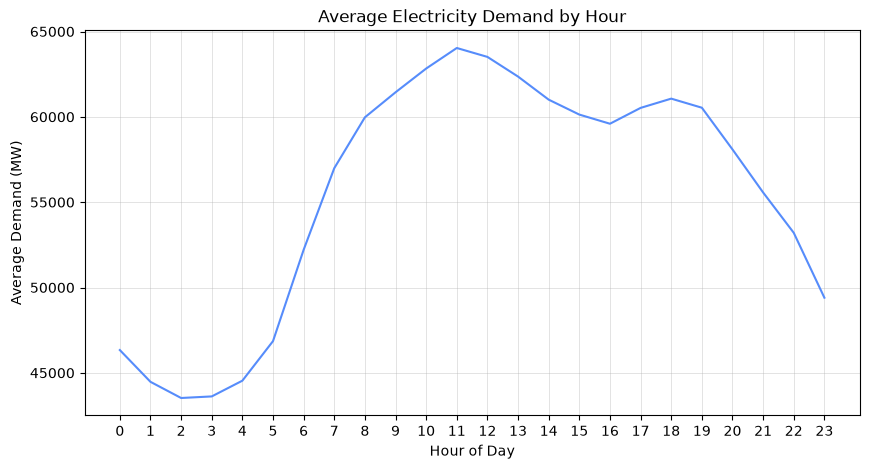

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(hourly_avg.index, hourly_avg.values)
plt.title("Average Electricity Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand (MW)")
plt.xticks(range(24))
plt.grid(True)

plt.show()

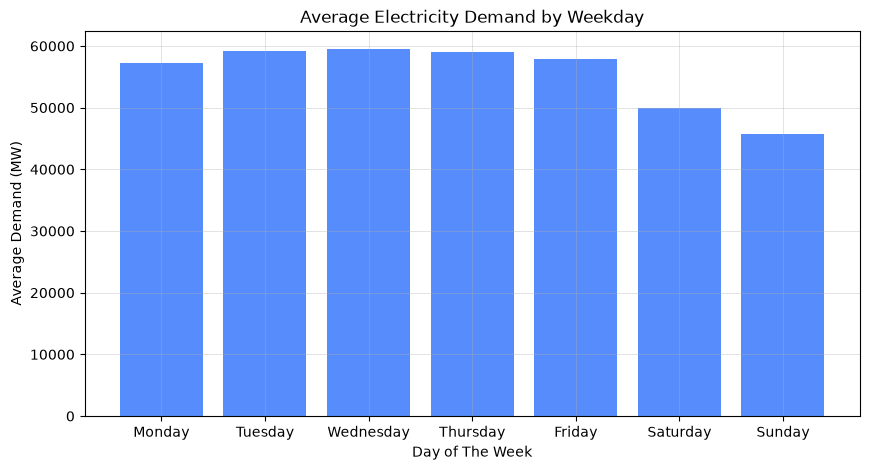

In [51]:
plt.figure(figsize=(10, 5))
plt.bar(weekly_avg.index, weekly_avg.values)
plt.title("Average Electricity Demand by Weekday")
plt.xlabel("Day of The Week")
plt.ylabel("Average Demand (MW)")
plt.xticks(ticks=range(7), labels=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
plt.grid(True)

plt.show()